In [ ]:
import rasterio
import xarray as xr
import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re

from pyproj import Transformer
from rasterio.transform import rowcol
from pyproj import Proj, transform
from rasterio.merge import merge
from rasterio.transform import from_bounds
from datetime import datetime, timedelta
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d

# Path to your merged raster file
raster_path = "H:/My Drive/NDVI_Exports//Merged/WY_NDVI_2018.tif"

# Read the merged raster file
with rasterio.open(raster_path) as src:
    # Read all bands into a numpy array
    stacked_data = src.read()  # shape: (bands, height, width)
    raster_crs = src.crs  # Get the raster CRS
    native_transform = src.transform  # Affine transformation matrix

print("Original Stacked Data Shape:", stacked_data.shape)

Original Stacked Data Shape: (46, 811, 1810)
Smoothed Data Shape: (46, 811, 1810)
Scaled Data Min: 0.0
Scaled Data Max: 1.0
Upper Quantile (97.5th percentile): 1.0
Minimum NDVI (per pixel): 0.0


In [ ]:
# Temporal smoothing function using a moving average
def smooth_temporal(data, window_size=3):
    """
    Smooths the temporal dimension of the stacked raster data using a moving average.

    Parameters:
    - data: numpy array of shape (bands, height, width)
    - window_size: size of the moving window (must be an odd integer)

    Returns:
    - smoothed_data: numpy array of shape (bands, height, width)
    """
    smoothed_data = uniform_filter1d(data, size=window_size, axis=0, mode='nearest')
    return smoothed_data


In [ ]:
# Step 1: Temporal smoothing
window_size = 3  # Define the moving window size (adjust as needed)
smoothed_data = smooth_temporal(stacked_data, window_size=window_size)

# Verify smoothing
print("Smoothed Data Shape:", smoothed_data.shape)

# Step 2: Replace all-NaN pixels
valid_mask = ~np.isnan(smoothed_data).all(axis=0)  # Mask for valid pixels
min_val = np.full(smoothed_data.shape[1:], np.nan)  # Default to NaN
upper_quantile = np.full(smoothed_data.shape[1:], np.nan)

# Only compute for valid pixels
min_val[valid_mask] = np.nanmin(smoothed_data[:, valid_mask], axis=0)
upper_quantile[valid_mask] = np.nanquantile(smoothed_data[:, valid_mask], 0.975, axis=0)

# Fill remaining NaNs with defaults
min_val = np.nan_to_num(min_val, nan=0.0)
upper_quantile = np.nan_to_num(upper_quantile, nan=1.0)

# Expand arrays for broadcasting
upper_quantile_expanded = upper_quantile[np.newaxis, :, :]
min_val_expanded = min_val[np.newaxis, :, :]

# Step 3: Scale NDVI values
epsilon = 1e-10
denominator = upper_quantile_expanded - min_val_expanded + epsilon
scaled_data = (smoothed_data - min_val_expanded) / denominator
scaled_data = np.clip(scaled_data, 0, 1)  # Ensure scaled values stay within [0, 1]

# Verify the range of scaled data
print("Scaled Data Min:", np.nanmin(scaled_data))
print("Scaled Data Max:", np.nanmax(scaled_data))
print("Upper Quantile (97.5th percentile):", np.nanmax(upper_quantile))
print("Minimum NDVI (per pixel):", np.nanmin(min_val))


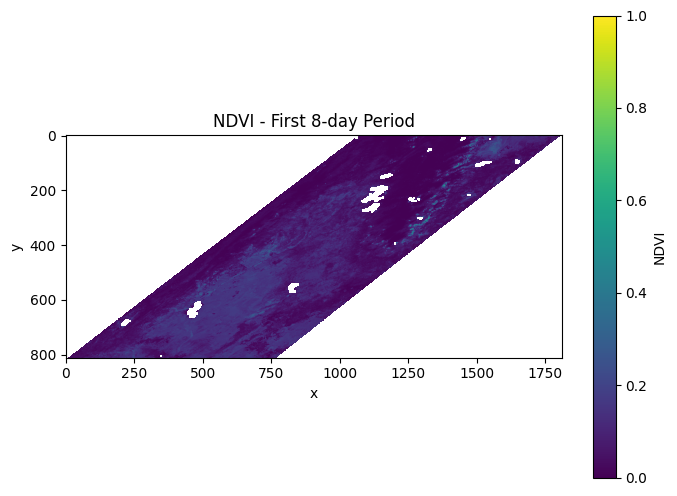

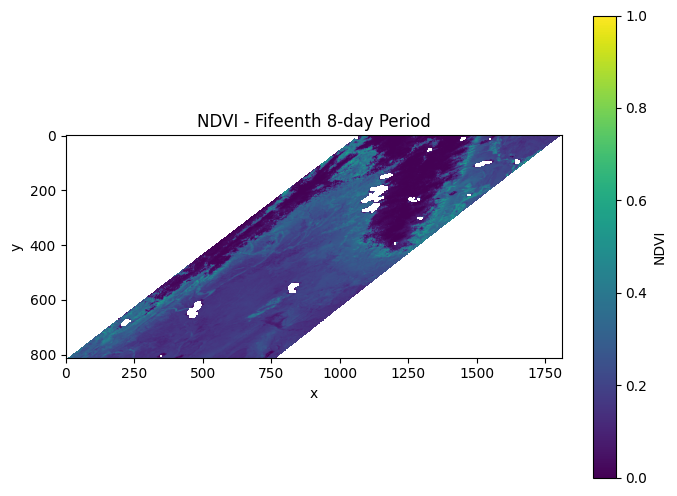

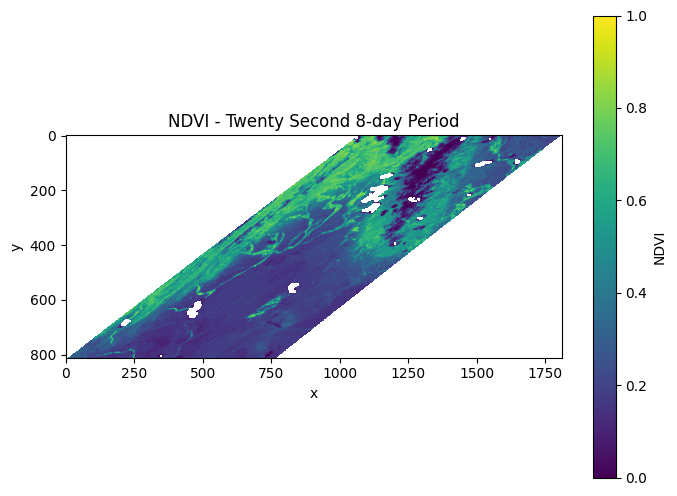

In [17]:

# Plot the first 8-day NDVI layer
plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[0, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - First 8-day Period")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[15, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - Fifeenth 8-day Period")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[22, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - Twenty Second 8-day Period")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [3]:
## define the DLC model

def dlc_model(time, xmidS, scalS, xmidA, scalA):
    return (1 / (1 + np.exp((xmidS - time) / scalS))) - (1 / (1 + np.exp((xmidA - time) / scalA)))


In [4]:
# years = list(range(2018, 2024))  # Use 2024 as the end point to include 2023
years = [2018, 2019, 2020, 2021]
years = [2018]

## get the dates
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year

dates = pd.to_datetime(dates)

## intial parameters to try for the DLC
dlc_bounds = ([30, 1, 167, 1], [228, 30, 288, 35])

## run the function for each pixel seperately
def fit_dlc_per_pixel(ndvi_data, time, dlc_bounds):
    if np.isnan(ndvi_data).any() or len(ndvi_data[~np.isnan(ndvi_data)]) < 4:
        return [np.nan] * 8  # return NaNs if insufficient data

    try:
        ## initial parameter guesses
        initial_guess = [130, 10, 230, 17]
        
        ## perform the curve fitting
        popt, pcov = curve_fit(dlc_model, time, ndvi_data, p0=initial_guess, bounds=dlc_bounds)
        
        ## extract standard errors from the covariance matrix
        perr = np.sqrt(np.diag(pcov))
        
        ## return parameters and standard errors
        return list(popt) + list(perr)
    
    except Exception as e:
        print(f"Error fitting pixel: {e}")
        return [np.nan] * 8

## process the data for each year seperately
def fit_dlc_for_year(ndvi_stack, dates, years, dlc_bounds):
    results = []
    
    for year in years:
        # Subset NDVI data to current year
        year_indices = [i for i, date in enumerate(dates) if date.year == year]
        ndvi_year = ndvi_stack[year_indices]
        time = np.array([date.timetuple().tm_yday for i, date in enumerate(dates) if date.year == year])
        
        # Initialize result array for current year
        dlc_params = np.full((*ndvi_year.shape[1:], 8), np.nan)
        
        # Loop over each pixel
        for row in range(ndvi_year.shape[1]):
            for col in range(ndvi_year.shape[2]):
                ndvi_pixel = ndvi_year[:, row, col]
                dlc_params[row, col, :] = fit_dlc_per_pixel(ndvi_pixel, time, dlc_bounds)
                
        results.append(dlc_params)
    
    return np.stack(results, axis=0)  # Shape: (years, rows, cols, params)


## fit the DLC model for each year
dlc_results = fit_dlc_for_year(scaled_data, dates, years, dlc_bounds)

print("DLC Parameters Shape:", dlc_results.shape) ## years, rows, columns, parameters

Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
DLC Parameters Shape: (1, 811, 1810, 8)


In [5]:
# Function to calculate fitted NDVI values for each pixel based on the DLC parameters
def calculate_fitted_vals(dlc_params, dates, values="daily"):
    time = np.arange(1, 366) if values == "daily" else np.arange(1, 366, 7)
    fitted_vals = np.full((dlc_params.shape[0], dlc_params.shape[1], len(time)), np.nan)
    
    for row in range(dlc_params.shape[0]):
        for col in range(dlc_params.shape[1]):
            params = dlc_params[row, col, :4]
            if np.isnan(params).any():
                continue  # Skip pixels with NaN parameters
            fitted_vals[row, col, :] = dlc_model(time, *params)
    
    return fitted_vals

# Function to calculate Instantaneous Rate of Green-up (IRG)
def calculate_irg(fitted_vals, sclIRG=True):
    # Calculate the difference along the time dimension (axis=2)
    irg = np.diff(fitted_vals, axis=2)
    
    # Pad the last day with NaN to keep the dimensions consistent
    irg = np.concatenate((irg, np.full(irg.shape[:-1] + (1,), np.nan)), axis=2)
    
    # Set negative IRG values to 0
    irg[irg < 0] = 0
    
    # Scale IRG values between 0 and 1 if required
    if sclIRG:
        irg_min = np.nanmin(irg)
        irg_max = np.nanmax(irg)
        if irg_max > irg_min:  # Prevent division by zero
            irg = (irg - irg_min) / (irg_max - irg_min)
    
    return irg


# Function to calculate max values and peak dates, with handling for all-NaN slices
def calculate_max_and_dates(values_array, time_points, func="max"):
    # Initialize arrays to hold results, filled with NaNs initially
    max_vals = np.full(values_array.shape[:2], np.nan)
    max_dates = np.full(values_array.shape[:2], np.nan)

    for row in range(values_array.shape[0]):
        for col in range(values_array.shape[1]):
            pixel_values = values_array[row, col, :]
            if np.isnan(pixel_values).all():
                continue  # Skip if all values are NaN for this pixel
            
            # Calculate max value and corresponding date
            max_vals[row, col] = np.nanmax(pixel_values)
            max_dates[row, col] = time_points[np.nanargmax(pixel_values)]
    
    return max_vals, max_dates

# Prepare time indices for date calculations
# years = [2018, 2019, 2020, 2021]
years = [2018]
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year
dates = pd.to_datetime(dates)

# Calculate fitted values and IRG for year 2017
time_points = np.arange(1, 366)  # Day of year for daily calculations
fitted_vals = calculate_fitted_vals(dlc_results[0, :, :, :], dates)  # for year 1, e.g., 2017
irg_vals = calculate_irg(fitted_vals)

# Calculate max values and dates
max_ndvi, max_ndvi_date = calculate_max_and_dates(fitted_vals, time_points, func="max")
max_irg, max_irg_date = calculate_max_and_dates(irg_vals, time_points, func="max")

print("Max NDVI Value:", max_ndvi)
print("Max NDVI date:", max_ndvi_date)

print("Max IRG Value:", max_irg)
print("Max IRG Date:", max_irg_date)

Max NDVI Value: [[       nan        nan        nan ... 0.89308858 0.81333275 0.85746474]
 [       nan        nan        nan ... 0.87857599 0.87891299 0.80269499]
 [       nan        nan        nan ... 0.89266522 0.7956187         nan]
 ...
 [       nan        nan 0.95708321 ...        nan        nan        nan]
 [       nan 0.96615128 0.94439247 ...        nan        nan        nan]
 [0.9458942  0.93377408 0.96494675 ...        nan        nan        nan]]
Max NDVI date: [[ nan  nan  nan ... 191. 185. 173.]
 [ nan  nan  nan ... 203. 189. 177.]
 [ nan  nan  nan ... 194. 188.  nan]
 ...
 [ nan  nan 142. ...  nan  nan  nan]
 [ nan 147. 143. ...  nan  nan  nan]
 [161. 156. 145. ...  nan  nan  nan]]
Max IRG Value: [[       nan        nan        nan ... 0.03354504 0.04152613 0.05614944]
 [       nan        nan        nan ... 0.03342296 0.03334454 0.03222184]
 [       nan        nan        nan ... 0.03350883 0.03209416        nan]
 ...
 [       nan        nan 0.15515676 ...        nan        n

In [ ]:
import rasterio
from rasterio.transform import rowcol
from pyproj import Transformer

latitude =  42.23412  # Replace with your latitude
longitude = -110.0903  # Replace with your longitude

transformer = Transformer.from_crs("EPSG:4326", raster_crs, always_xy=True)
x, y = transformer.transform(longitude, latitude)

print(x, y)


-9087554.963926675 4677641.8890606025


Latitude: 42.27412, Longitude: -110.0903 -> Row: 626, Col: 492


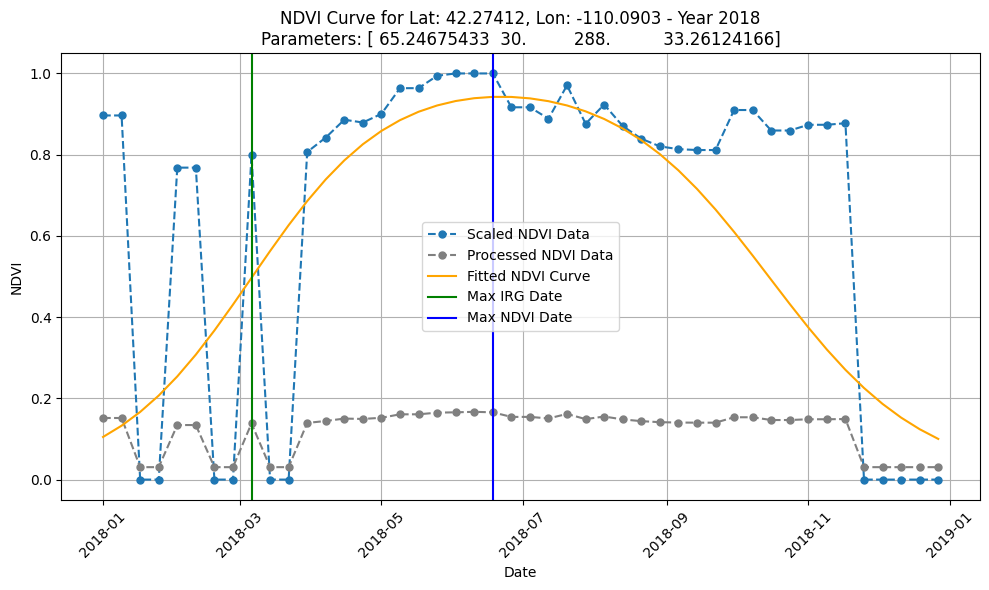

Latitude: 42.47383, Longitude: -109.2682 -> Row: 530, Col: 908


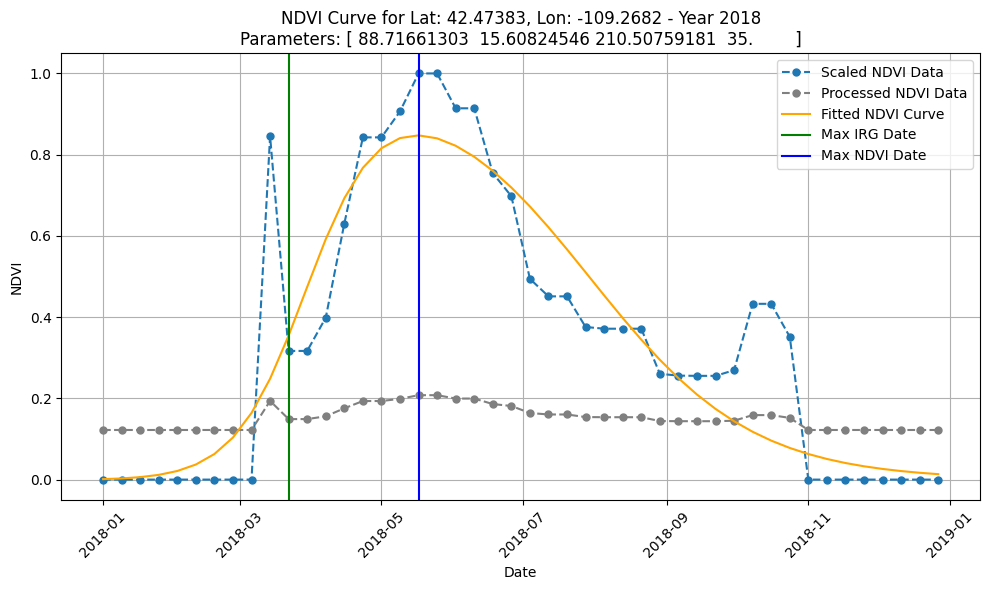

In [15]:
from rasterio.transform import rowcol

# Function to calculate fitted NDVI values for specific dates
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot NDVI and curves for a specific latitude and longitude
def plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, lat, lon, transform, years):
    
    # Convert latitude and longitude to row and column indices
    transformer = Transformer.from_crs("EPSG:4326", raster_crs, always_xy=True)
    x, y = transformer.transform(longitude, latitude)

    row, col = rowcol(transform, x, y)
    print(f"Latitude: {lat}, Longitude: {lon} -> Row: {row}, Col: {col}")
    
    # Plotting setup
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing
    
    for i, year in enumerate(years):
        # Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        # Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        # Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        # Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = scaled_data[year_indices, row, col]
        ndvi_values_raw = stacked_data[year_indices, row, col]
        
        # Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Scaled NDVI Data", linestyle='--', markersize=5)
        ax[i].plot(year_dates, ndvi_values_raw, 'o', label="Processed NDVI Data", linestyle='--', markersize=5, color = "grey")
        
        # Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Lat: {lat}, Lon: {lon} - Year {year}\nParameters: {params}")
            
            # Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='-', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='-', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Lat: {lat}, Lon: {lon} - Year {year} (No Fit)")
        
        # Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()


## Some weird places in WY that were different than jerod's code
# -110.0903 42.23412
# -109.2682 42.47383

latitude =  42.27412  # Replace with your latitude
longitude = -110.0903  # Replace with your longitude
transform = native_transform  # Use the transform from your mosaic

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, latitude, longitude, transform, years)

latitude = 42.47383  # Replace with your latitude
longitude = -109.2682  # Replace with your longitude

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, latitude, longitude, transform, years)


In [ ]:
# Function to calculate fitted NDVI values for specific dates (8-day intervals) based on DLC parameters
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot fitted and raw NDVI data with lines for max IRG and NDVI dates
def plot_ndvi_pixel(dlc_results, stacked_data, scaled_data, dates, row, col):
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing when there's only one subplot
    
    for i, year in enumerate(years):
        ## Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        ## Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        ## Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        ## Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = stacked_data[year_indices, row, col]
        ndvi_values_scaled = scaled_data[year_indices, row, col]
        
        ## Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Raw NDVI Data", linestyle='-', markersize=5, color = "grey")
        ax[i].plot(year_dates, ndvi_values_scaled, 'o', label="Scaled NDVI Data", linestyle='-', markersize=5, color = "blue")
        
        ## Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Pixel ({row}, {col}) - Year {year}\nParameters: {params}")
            
            ## Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='--', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='--', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Pixel ({row}, {col}) - Year {year} (No Fit)")
        
        ## Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

## Specify row and column indices for the pixel you want to analyze
row_index = 500 
col_index = 500  

## Plot the raw and fitted NDVI data for the specified pixel across years
plot_ndvi_pixel(dlc_results, stacked_data, scaled_data, dates, row_index, col_index)